# ניתוח מכתבי אזהרה של ה-FDA

המחברת טוענת את `warning-letters.xlsx`, מסננת למכתבי **מכשור רפואי (CDRH)**, מציגה מגמות לפי שנה, ושולפת מילות מפתח מתוך עמודת `Subject` בעזרת TF-IDF.

**איך להריץ:** עבור על התאים מלמעלה למטה. תאי Colab / Selenium הם אופציונליים ולא נדרשים לניתוח הבסיסי.


## 1. ייבוא ספריות

כל ה-imports של הניתוח והסריקה הבסיסית נמצאים כאן. הריצו את התא הזה פעם אחת בתחילת העבודה.


In [1]:
import sys
import time
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from bs4 import BeautifulSoup
from sklearn.feature_extraction.text import TfidfVectorizer
from tqdm import tqdm

%matplotlib inline


## 2. טעינת קובץ האקסל

מחפשים את `warning-letters.xlsx` בתיקייה הנוכחית, ב-`/content/` (Colab), או ב-Google Drive. אם הקובץ לא נמצא — מורידים אותו מ-GitHub.


In [3]:
candidates = [
    Path("warning-letters.xlsx"),
    Path("/content/warning-letters.xlsx"),
    Path("/content/drive/MyDrive/warning-letters.xlsx"),
]
file_path = next((p for p in candidates if p.exists()), None)

if file_path is None:
    github_url = (
        "https://github.com/Bar-Hai-Cohen/FDA_Warning_Letters_Analysis_Project/"
        "raw/main/warning-letters.xlsx"
    )
    file_path = Path("warning-letters.xlsx")
    print("הקובץ לא נמצא מקומית — מוריד מ-GitHub...")
    urllib.request.urlretrieve(github_url, file_path)

print("מתחיל טעינת קובץ אקסל... זה עשוי לקחת דקה בגלל גודל הקובץ")
print(f"נתיב הקובץ: {file_path.resolve()}")

try:
    df_all = pd.read_excel(file_path)
    print(f"הצלחנו! נטענו {len(df_all)} שורות מהאקסל.")
    print(f"עמודות: {list(df_all.columns)}")
except Exception as e:
    print(f"חלה שגיאה: {e}")
    print("אם זה Colab: Files → Upload → warning-letters.xlsx, ואז הריצו את התא שוב.")
    print("או הריצו: !pip install openpyxl")
    raise


הקובץ לא נמצא מקומית — מוריד מ-GitHub...
מתחיל טעינת קובץ אקסל... זה עשוי לקחת דקה בגלל גודל הקובץ
נתיב הקובץ: /content/warning-letters.xlsx
הצלחנו! נטענו 3474 שורות מהאקסל.
עמודות: ['Posted Date', 'Letter Issue Date', 'Company Name', 'Issuing Office', 'Subject', 'Response Letter', 'Closeout Letter']


## 3. סינון למכשור רפואי (CDRH)

בלי הסינון הגרפים מושפעים ממכתבי טבק ותרופות. כאן נשארים רק משרדים שקשורים ל-Device / Radiological Health / CDRH.


In [5]:
df = df_all.copy()

office_col = "Issuing Office" if "Issuing Office" in df.columns else "Center"
if office_col in df.columns:
    df = df[
        df[office_col].fillna("").str.contains(
            r"Device|Radiological Health|CDRH",
            case=False,
            regex=True,
        )
    ].copy()

df_cdrh = df.copy()

print(f"עמודה לסינון: {office_col}")
print(f"אחרי סינון ל-CDRH נשארו {len(df)} מכתבי מכשור רפואי.")


עמודה לסינון: Issuing Office
אחרי סינון ל-CDRH נשארו 259 מכתבי מכשור רפואי.


## 4. ניקוי תאריכים

ממירים את תאריך הפרסום / ההנפקה ל-datetime ויוצרים עמודת `Year` לגרף המגמות.


In [6]:
date_col = "Issue Date" if "Issue Date" in df.columns else "Posted Date"

if date_col in df.columns:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    df["Year"] = df[date_col].dt.year
    print(f"עמודת תאריך בשימוש: {date_col}")
    print("מספר מכתבים לפי שנה:")
    print(df["Year"].value_counts().sort_index())
else:
    print("לא נמצאה עמודת תאריך מתאימה.")


עמודת תאריך בשימוש: Posted Date
מספר מכתבים לפי שנה:
Year
2021    60
2022    19
2023    36
2024    45
2025    82
2026    17
Name: count, dtype: int64


## 5. גרף: מכתבי אזהרה לפי שנה

כמות מכתבי CDRH בכל שנה. 2026 עשויה להיות חלקית כי השנה עדיין לא הסתיימה.


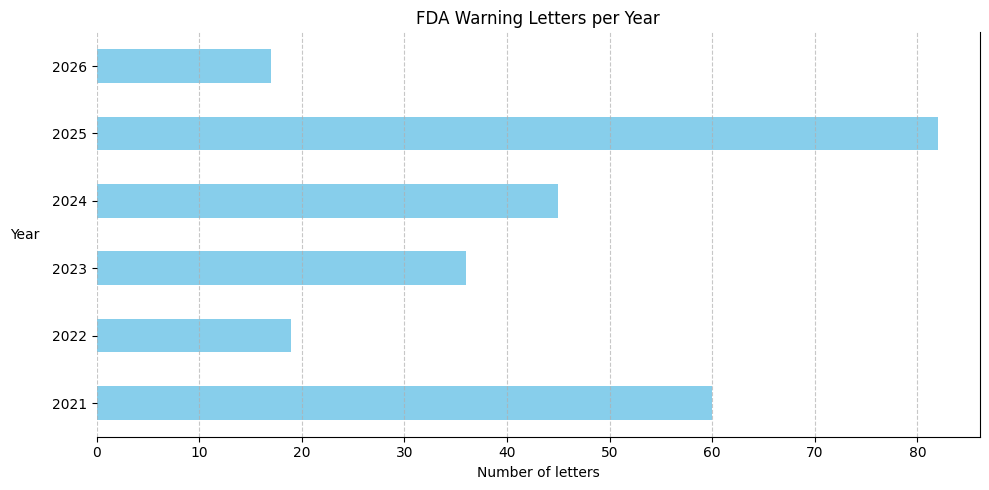

In [8]:
if "Year" in df.columns:
    plt.figure(figsize=(10, 5))
    # צובר נתונים
    year_counts = df["Year"].value_counts().sort_index()
    # יצירת גרף עם תאריכים אופקית ועמודות Y גם אופקי (barh)
    ax = year_counts.plot(kind="barh", color="skyblue")
    plt.title("FDA Warning Letters per Year")
    plt.xlabel("Number of letters")
    plt.ylabel("Year", rotation=0, ha='left', va="center", labelpad=30)  # תווית אנכית בשורה אופקית
    
    # להוריד גריד עליון ושמאלי, להשאיר תחתון וימני
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.yaxis.grid(False)
    ax.xaxis.grid(True, linestyle="--", alpha=0.7)
    
    plt.tight_layout()
    plt.show()
else:
    print("אין עמודת Year — דלגו על הגרף הזה.")


## 6. TF-IDF — מילות מפתח מתוך Subject

שולפים את 25 המילים המשמעותיות ביותר מעמודת `Subject` (בלי stop-words באנגלית).


In [9]:
subjects = df["Subject"].fillna("Missing").astype(str)

tfidf = TfidfVectorizer(stop_words="english", max_features=25)
tfidf_matrix = tfidf.fit_transform(subjects)

weights = tfidf_matrix.sum(axis=0).getA1()
words = tfidf.get_feature_names_out()
keywords_df = pd.DataFrame({"Word": words, "Weight": weights}).sort_values(
    by="Weight", ascending=False
)

print("--- 10 המילים המובילות שמצאנו ---")
print(keywords_df.head(10))


--- 10 המילים המובילות שמצאנו ---
           Word     Weight
17      medical  59.985809
22          qsr  59.142916
5          cgmp  59.142916
9       devices  58.031132
2   adulterated  55.348031
8        device  35.443932
18   misbranded  35.397376
19          pma  23.888596
4      approval  17.228480
20    premarket  17.228480


## 7. גרף: מילות מפתח רגולטוריות

המילים עם המשקל הגבוה ביותר ב-TF-IDF. במכתבי מכשור רפואי צפויות מילים כמו `medical`, `cgmp`, `qsr`, `devices`.


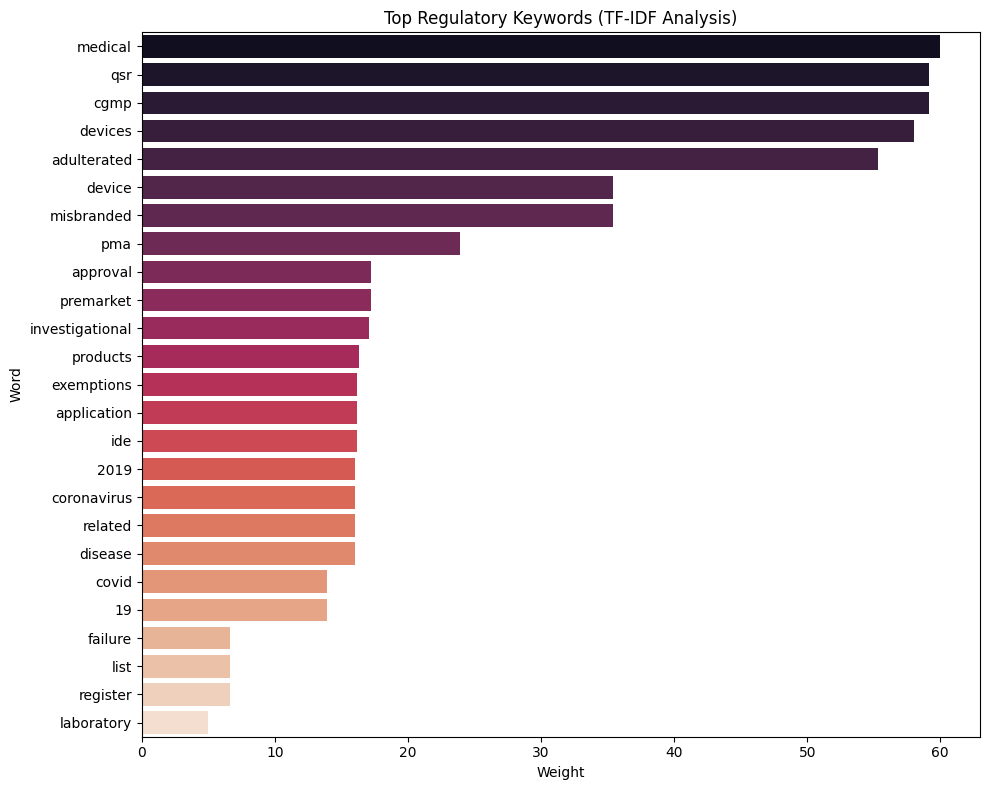

In [10]:
plt.figure(figsize=(10, 8))
sns.barplot(
    data=keywords_df,
    x="Weight",
    y="Word",
    hue="Word",
    palette="rocket",
    legend=False,
)
plt.title("Top Regulatory Keywords (TF-IDF Analysis)")
plt.tight_layout()
plt.show()


## 8. N-grams — צירופי מילים מתוך Subject

אותו רעיון כמו TF-IDF, אבל עם צירופים של 1–3 מילים (`failure to`, `lack of` וכו'). רץ על אותם מכתבי CDRH שסוננו למעלה.


In [11]:
def get_full_text_by_meta(company, date):
    search_query = f"FDA Warning Letter {company} {date}"
    return "Search logic needed"


df_cdrh["Subject_Clean"] = df_cdrh["Subject"].fillna("").astype(str)

tfidf_ngrams = TfidfVectorizer(stop_words="english", max_features=50, ngram_range=(1, 3))
tfidf_ngrams_matrix = tfidf_ngrams.fit_transform(df_cdrh["Subject_Clean"])

ngram_words = tfidf_ngrams.get_feature_names_out()
ngram_importance = tfidf_ngrams_matrix.sum(axis=0).getA1()
ngrams_df = pd.DataFrame(
    {"Word": ngram_words, "Importance": ngram_importance}
).sort_values(by="Importance", ascending=False)

print(f"עובדים על {len(df_cdrh)} מכתבים מהאקסל שלך.")
print()
print("--- צירופי מילים משמעותיים שמצאנו (N-grams) ---")
print(ngrams_df.head(15))


עובדים על 259 מכתבים מהאקסל שלך.

--- צירופי מילים משמעותיים שמצאנו (N-grams) ---
                           Word  Importance
30                      medical   38.766176
9                      cgmp qsr   37.025923
44                          qsr   37.025923
8                          cgmp   37.025923
17                      devices   35.908517
31              medical devices   35.908517
45                  qsr medical   35.732321
10             cgmp qsr medical   35.732321
46          qsr medical devices   35.732321
1                   adulterated   35.716344
33                   misbranded   35.556136
32  medical devices adulterated   34.131381
18          devices adulterated   34.131381
14                       device   25.700189
2        adulterated misbranded   20.681573


## 9. סריקת אינדקס מכתבי אזהרה באתר ה-FDA

שתי פונקציות:

1. `get_warning_letters_links` — שולפת קישורים מעמודי האינדקס.
2. `fetch_letter_content` — שולפת את תוכן המכתב עצמו.


In [15]:
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36"
    )
}


def get_warning_letters_links(category="Medical Service", max_pages=3):
    '''שולף את רשימת הקישורים למכתבי אזהרה מתוך עמודי האינדקס של ה-FDA.'''
    base_url = (
        "https://www.fda.gov/inspections-compliance-enforcement-and-criminal-investigations/"
        "compliance-actions-and-activities/warning-letters"
    )
    letters_data = []

    print(f"מחפש מכתבים בקטגוריה: {category}...")

    for page in range(0, max_pages):
        params = {
            "field_warning_letter_office_target_id": category,
            "page": page,
        }
        url = f"{base_url}?{urllib.parse.urlencode(params)}"

        try:
            req = urllib.request.Request(url, headers=HEADERS)
            with urllib.request.urlopen(req, timeout=30) as response:
                soup = BeautifulSoup(response.read(), "html.parser")

            table = soup.find("table")
            if not table:
                break

            links = table.find_all("a")
            page_added = 0

            for link in links:
                href = link.get("href", "")
                if "/warning-letters/" in href:
                    full_url = urllib.parse.urljoin("https://www.fda.gov", href)
                    if full_url not in [item["url"] for item in letters_data]:
                        letters_data.append(
                            {
                                "title": link.get_text(strip=True),
                                "url": full_url,
                            }
                        )
                        page_added += 1

            if page_added == 0:
                break

        except Exception as e:
            print(f"שגיאה בסריקת עמוד אינדקס {page}: {e}")
            break

    print(f"Found {len(letters_data)} letters to download.")
    return pd.DataFrame(letters_data)


def fetch_letter_content(url):
    '''שולף את התוכן של מכתב אזהרה ספציפי.'''
    try:
        req = urllib.request.Request(url, headers=HEADERS)
        with urllib.request.urlopen(req, timeout=30) as response:
            html = response.read().decode("utf-8")

        soup = BeautifulSoup(html, "html.parser")
        main = soup.find("main") or soup.find("article") or soup.find("body")

        if main:
            return main.get_text("\n", strip=True)
        return "No content found"
    except Exception as e:
        return f"Error: {str(e)}"


### הרצת הסריקה ושמירה ל-CSV

ניתן להגדיל את `max_pages` לפי הצורך. יש השהייה של שנייה בין מכתבים כדי לא להעמיס על השרת.


In [14]:
df_letters = get_warning_letters_links(category="Medical Service", max_pages=2)

if not df_letters.empty:
    print()
    print("מושך את תוכן המכתבים (זה עשוי לקחת קצת זמן)...")
    tqdm.pandas()

    def safe_fetch(url):
        time.sleep(1)
        return fetch_letter_content(url)

    df_letters["Full_Text"] = df_letters["url"].progress_apply(safe_fetch)
    df_letters.to_csv("fda_medical_service_letters.csv", index=False, encoding="utf-8-sig")
    print()
    print("הסתיים בהצלחה! הקובץ fda_medical_service_letters.csv מוכן.")
else:
    print("לא נמצאו מכתבים בקטגוריה המבוקשת.")


מחפש מכתבים בקטגוריה: Medical Service...
Found 10 letters to download.

מושך את תוכן המכתבים (זה עשוי לקחת קצת זמן)...


100%|██████████| 10/10 [00:11<00:00,  1.12s/it]


הסתיים בהצלחה! הקובץ fda_medical_service_letters.csv מוכן.


## 11. התקנת Chrome / Chromedriver (Google Colab בלבד)

התאים הבאים מיועדים ל-Colab. אין צורך להריץ אותם לניתוח המקומי על האקסל.


In [ ]:
!apt-get update
!apt-get install -y chromium-browser
!apt-get install -y chromium-chromedriverמה
!pip install selenium

sys.path.insert(0, "/usr/lib/chromium-browser/chromedriver")
print("התקנה הסתיימה בהצלחה!")


## 12. שליפת טקסט מלא עם Selenium (Colab)

מחפש בגוגל מכתב אזהרה לפי שם חברה, נכנס לקישור של FDA, ושולף את הטקסט מתוך `main`.

רץ כברירת מחדל על 3 החברות הראשונות בקובץ.


In [ ]:
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By


def fetch_full_text(company_name):
    if pd.isna(company_name):
        return "שם חסר"

    options = Options()
    options.add_argument("--headless")
    options.add_argument("--no-sandbox")
    options.add_argument("--disable-dev-shm-usage")

    service = Service("/usr/bin/chromedriver")
    driver = webdriver.Chrome(service=service, options=options)
    try:
        query = f"site:fda.gov warning letter {company_name}".replace(" ", "+")
        driver.get(f"https://www.google.com/search?q={query}")
        time.sleep(2)

        links = driver.find_elements(By.TAG_NAME, "a")
        target_url = None
        for link in links:
            url = link.get_attribute("href")
            if url and "fda.gov/inspections" in url:
                target_url = url
                break

        if target_url:
            driver.get(target_url)
            time.sleep(3)
            return driver.find_element(By.TAG_NAME, "main").text
        return "לא נמצא קישור"
    except Exception:
        return "שגיאה טכנית בשליפה"
    finally:
        driver.quit()


try:
    selenium_path = Path("warning-letters (1).csv")
    if not selenium_path.exists():
        selenium_path = file_path

    df_selenium = pd.read_excel(selenium_path)
    df_sample = df_selenium.head(3).copy()
    print("מתחיל שליפה עבור 3 חברות ראשונות...")

    results = []
    for name in tqdm(df_sample["Company Name"]):
        results.append(fetch_full_text(name))

    df_sample["Full_Text"] = results

    print()
    print("--- הצלחה! הנה התוצאות שנשלפו: ---")
    print(df_sample[["Company Name", "Full_Text"]])
except Exception as e:
    print(f"שגיאה בהרצה: {e}")
